In [13]:
from pathlib import Path
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np

logs = Path.cwd()  # this notebook lives in logs/, next to the CSVs from log_csv.py

sens2 = pd.read_csv(logs / 'sens2.csv')

# tick_ms restarts at every reboot, so plot one run at a time
print('Runs in sens2.csv:', sorted(sens2['run'].unique()))
run = 1  # pick which run to plot
s2 = sens2[sens2['run'] == run]
s2_t = (s2['tick_ms'].to_numpy() - s2['tick_ms'].iloc[0]) / 1000.0

# Firmware attitude, as logged (computed with the board's y and z axes swapped)
roll = s2['roll_deg'].to_numpy()
pitch = s2['pitch_deg'].to_numpy()
yaw = s2['yaw_deg'].to_numpy()

# The flight software swapped y and z, so swap them back to get the board's real axes
gyr_x = s2['gyrX_dps'].to_numpy()
gyr_y = s2['gyrZ_dps'].to_numpy()
gyr_z = s2['gyrY_dps'].to_numpy()

Runs in sens2.csv: [np.int64(1), np.int64(2)]


# Attitude (Roll movement)

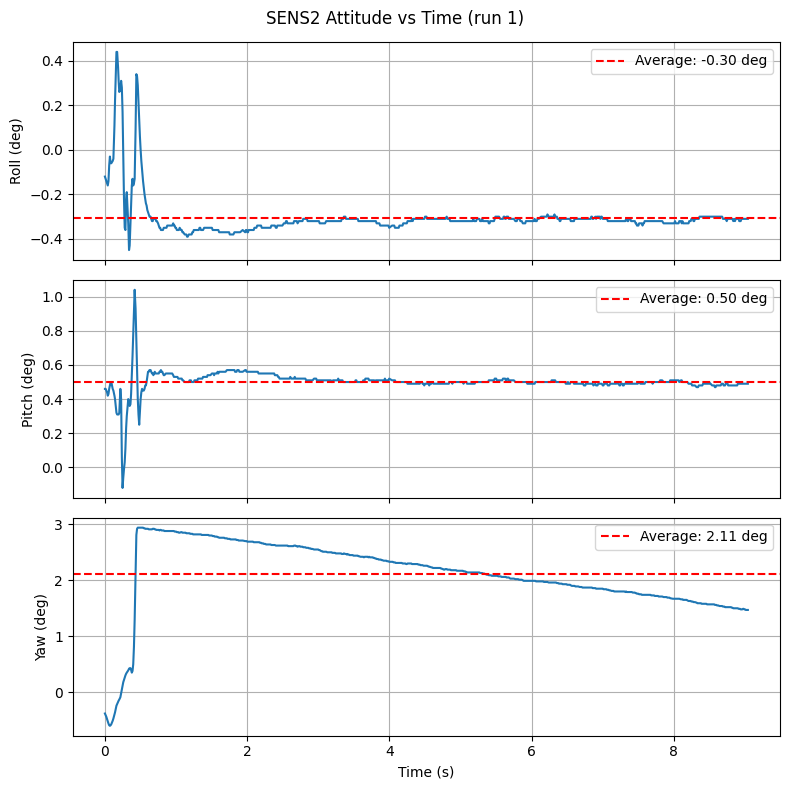

In [14]:
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 8))
for ax, angle, name in zip(axs, [roll, pitch, yaw], ['Roll', 'Pitch', 'Yaw']):
    ax.plot(s2_t, angle)
    avg = np.mean(angle)
    ax.axhline(avg, color='r', linestyle='--', label=f'Average: {avg:.2f} deg')
    ax.legend(loc='upper right')
    ax.set_ylabel(f'{name} (deg)')
    ax.grid(True)
axs[-1].set_xlabel('Time (s)')
fig.suptitle(f'SENS2 Attitude vs Time (run {run})')
plt.tight_layout()
plt.show()

# Gyro Rates (Pitch movement)

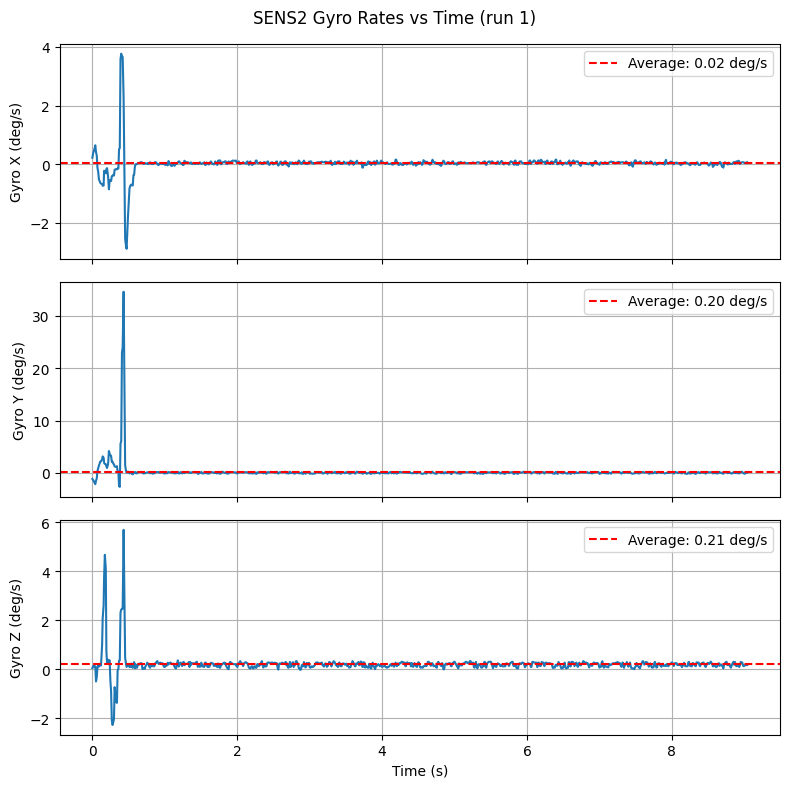

In [15]:
fig, axs = plt.subplots(3, 1, sharex=True, figsize=(8, 8))
for ax, rate, name in zip(axs, [gyr_x, gyr_y, gyr_z], ['X', 'Y', 'Z']):
    ax.plot(s2_t, rate)
    avg = np.mean(rate)
    ax.axhline(avg, color='r', linestyle='--', label=f'Average: {avg:.2f} deg/s')
    ax.legend(loc='upper right')
    ax.set_ylabel(f'Gyro {name} (deg/s)')
    ax.grid(True)
axs[-1].set_xlabel('Time (s)')
fig.suptitle(f'SENS2 Gyro Rates vs Time (run {run})')
plt.tight_layout()
plt.show()

In [16]:
avg_gz = np.mean(gyr_z)
slope = (yaw[-1] - yaw[0]) / (s2_t[-1] - s2_t[0])
print(f'Average gyro X: {avg_gz:.2f} deg/s, slope: {slope:.2f} deg/s')

Average gyro X: 0.21 deg/s, slope: 0.20 deg/s
